In [1]:
import torch
import os
import monai.transforms as mt
import monai.data as md
import scipy.io as sio
import numpy as np
from liutuo_utils import compare_3d_jet,compare_3d,donkey_noise_like
import matplotlib.pyplot as plt
import pandas as pd


device_id =5
# 设置 PyTorch 的默认 CUDA 设备
torch.cuda.set_device(device_id)

# 确认当前默认 CUDA 设备
current_device = torch.cuda.current_device()
print(f"Switched to CUDA device: {current_device}")

/home/pnxc/Anaconda3/envs/xiaochou/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Switched to CUDA device: 5


In [2]:
import torch
from transformers import AutoProcessor, AutoModel
import torch.nn.functional as F

# 1. 加载 BiomedCLIP 模型和处理器
local_model_path = "/home/ssddata/liutuo/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()
# 加载优化后的描述
fdg_text_optimized = (
    "FDG PET is a functional brain imaging technique that visualizes the dynamic changes in glucose metabolism, directly linked to neuronal energy demands and synaptic activity. It serves as a tool to assess functional connectivity and energy utilization across brain regions. Areas with decreased metabolic activity, such as those affected by neurodegenerative diseases, should exhibit reduced signal intensity. High-intensity metabolic hotspots in gray matter (e.g., the cerebral cortex and basal ganglia) are key markers of neuronal activity. "
    
)

av45_text_optimized = (
    "AV45 PET is a molecular imaging technique that highlights the static distribution of amyloid-beta plaques, a critical pathological marker of Alzheimer's disease. This imaging modality provides a spatial map of amyloid deposition in cortical regions (e.g., the temporal, parietal, and frontal lobes) and can distinguish amyloid-positive areas from amyloid-negative white matter regions. The primary focus is on identifying amyloid deposition patterns to assess disease progression and pathological burden."
    
)

# 提取特征向量
texts_optimized = [fdg_text_optimized, av45_text_optimized]
inputs_optimized = processor(text=texts_optimized, return_tensors="pt", padding=True).to(device)

with torch.no_grad():
    text_features_optimized = model.get_text_features(**inputs_optimized)

# 计算相似度
fdg_feature_optimized = text_features_optimized[0]
fdg_feature_optimized=fdg_feature_optimized.unsqueeze(0)
av45_feature_optimized = text_features_optimized[1]
av45_feature_optimized =av45_feature_optimized.unsqueeze(0)

cosine_similarity_optimized = F.cosine_similarity(fdg_feature_optimized, av45_feature_optimized).item()

print(f"Cosine similarity between optimized FDG PET and AV45 PET features: {cosine_similarity_optimized:.4f}")


Cosine similarity between optimized FDG PET and AV45 PET features: 0.8205


In [5]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import json

# 数据目录（保持不变）
base_dir = "/home/ssddata/liutuo/liutuo_data/test1"
mri_dir = "/home/ssddata/liutuo/liutuo_data/test1/MRI"
av45_dir = "/home/ssddata/liutuo/liutuo_data/test1/AV45"
fdg_dir = "/home/ssddata/liutuo/liutuo_data/test1/FDG"
csv_path = os.path.join(base_dir, "test_filtered_subjects_with_description.csv")

# JSON 文件保存路径（保持不变）
train_json_path = "/home/ssddata/liutuo/liutuo_data/test1/train_data_with_description.json"
val_json_path = "/home/ssddata/liutuo/liutuo_data/test1/val_data_with_description.json"

# 加载 CSV 文件（保持不变）
csv_data = pd.read_csv(csv_path)
csv_dict = csv_data.set_index("Subject ID")["Description"].to_dict()

# 获取文件列表（保持不变）
mri_files = sorted(os.listdir(mri_dir))
av45_files = sorted(os.listdir(av45_dir))
fdg_files = sorted(os.listdir(fdg_dir))

def get_subject_id(filename):
    """从文件名中提取统一的 subject ID（前三个部分，如 '002_S_0295'）"""
    parts = filename.split('_')
    return f"{parts[0]}_{parts[1]}_{parts[2]}"

# 使用统一的 get_subject_id 处理所有文件（保持不变）
mri_dict = {get_subject_id(f): os.path.join(mri_dir, f) for f in mri_files}
av45_dict = {get_subject_id(f): os.path.join(av45_dir, f) for f in av45_files}
fdg_dict = {get_subject_id(f): os.path.join(fdg_dir, f) for f in fdg_files}

# 匹配文件并加入描述信息和 Subject ID
paired_data = []
for patient_id, mri_file in mri_dict.items():
    if patient_id in av45_dict and patient_id in fdg_dict:
        # 检查描述信息是否存在
        description = csv_dict.get(patient_id, None)  # 从 csv_dict 中获取 Description 信息
        # 构建数据条目
        paired_data.append({
            "name": patient_id,  # 添加 name 字段
            "mri": os.path.join(mri_dir, mri_file),
            "av45": os.path.join(av45_dir, av45_dict[patient_id]),
            "fdg": os.path.join(fdg_dir, fdg_dict[patient_id]),
            "description": description  # 加入 Description 信息
        })

print(f"Total matched pairs with description: {len(paired_data)}")
# 在 paired_data 中新增键 fdg_index 和 av45_index
for idx, data in enumerate(paired_data):
    data["fdg_index"] = idx  # 将样本在 paired_data 中的索引作为 fdg_index
    data["av45_index"] = idx

import torch
from transformers import AutoTokenizer, AutoModel

# 示例：假设已经加载 BiomedCLIP 模型和处理器
# 这里替换为您实际使用的 BiomedCLIP 模型和 tokenizer
local_model_path = "/home/ssddata/liutuo/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()


# 假设 paired_data 已经加载
modal_information = [data["description"] for data in paired_data if data["description"] is not None]

# 对描述信息进行 Tokenizer 编码
text_inputs = processor(
    modal_information,
    padding=True,
    truncation=True,
    return_tensors="pt",
    max_length=256 # 根据模型输入限制选择合适的 max_length
).to(device)

# 转化为 BiomedCLIP 嵌入
with torch.no_grad():
    desc_text_features = model.get_text_features(text_inputs['input_ids'])  # 使用模型方法提取嵌入
    print(f"Shape of features: {desc_text_features.shape}, Dtype: {desc_text_features.dtype}")

# 划分训练集和验证集
train_data, val_data = train_test_split(paired_data, test_size=1, random_state=42)

print(f"Training set size: {len(train_data)}")
print(f"Validation set size: {len(val_data)}")

# 保存到 JSON 文件
with open(train_json_path, "w") as f:
    json.dump(train_data, f, indent=4)

with open(val_json_path, "w") as f:
    json.dump(val_data, f, indent=4)

print(f"Saved train data to: {train_json_path}")
print(f"Saved validation data to: {val_json_path}")

Total matched pairs with description: 2
Shape of features: torch.Size([2, 512]), Dtype: torch.float32
Training set size: 1
Validation set size: 1
Saved train data to: /home/ssddata/liutuo/liutuo_data/test1/train_data_with_description.json
Saved validation data to: /home/ssddata/liutuo/liutuo_data/test1/val_data_with_description.json


In [6]:
# 验证训练集
with open(train_json_path, "r") as f:
    train_data = json.load(f)
print(f"Loaded {len(train_data)} training samples.")
print("First training sample:", train_data[0])

# 验证验证集
with open(val_json_path, "r") as f:
    val_data = json.load(f)
print(f"Loaded {len(val_data)} validation samples.")
print("First validation sample:", val_data[0])



Loaded 1 training samples.
First training sample: {'name': '037_S_0552', 'mri': '/home/ssddata/liutuo/liutuo_data/test1/MRI/037_S_0552_MRI_registered.nii.gz', 'av45': '/home/ssddata/liutuo/liutuo_data/test1/AV45/037_S_0552_AV45_registered.nii.gz', 'fdg': '/home/ssddata/liutuo/liutuo_data/test1/FDG/037_S_0552_FDG_registered.nii.gz', 'description': 'Subject is a 60-year-old female with a weight of 65.4 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 0.5. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 27. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 7. The Neuropsychiatric Inventory Questionnaire (NPI-Q) Total Score, assessing neuropsy

In [7]:
from monai.transforms import Compose, LoadImaged, Lambdad, EnsureChannelFirstd, Orientationd, CropForegroundd, \
    HistogramNormalized, ResizeWithPadOrCropd, Spacingd, NormalizeIntensityd, ScaleIntensityd
from monai.data import CacheDataset, DataLoader
import nibabel as nib
import numpy as np
import json

import monai.transforms as mt

# 定义 transform 函数
def fdg_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), fdg_feature_optimized], dim=0)

def av45_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), av45_feature_optimized], dim=0)


# 自定义加载函数
def mat_load(filepath):
    """
    使用 nibabel 加载 NIfTI 文件，并转换为 NumPy 数组。
    """
    return nib.load(filepath).get_fdata()

# 加载 JSON 文件
train_json_path = "/home/ssddata/liutuo/liutuo_data/test1/train_data_with_description.json"
val_json_path = "/home/ssddata/liutuo/liutuo_data/test1/val_data_with_description.json"

# 加载 JSON 文件
with open(train_json_path, "r") as f:
    train_data = json.load(f)

with open(val_json_path, "r") as f:
    val_data = json.load(f)

# 转换数据格式
train_data = [
    {
        "name": item["name"],
        "mri": item["mri"],
        "av45": item["av45"],
        "fdg": item["fdg"],
        "description": item.get("description", {}),  # 确保 description 存在
        "fdg_index": item.get("fdg_index"),  # 保留 fdg_index
        "av45_index": item.get("av45_index"),  # 保留 av45_index
    }
    for item in train_data
]

val_data = [
    {
        "name": item["name"],
        "mri": item["mri"],
        "av45": item["av45"],
        "fdg": item["fdg"],
        "description": item.get("description", {}),  # 确保 description 存在
        "fdg_index": item.get("fdg_index"),  # 保留 fdg_index
        "av45_index": item.get("av45_index"),  # 保留 av45_index
    }
    for item in val_data
]



# 构建数据增强 pipeline
# 定义训练集数据增强流程
train_transforms = mt.Compose([
    mt.Lambdad(keys=["mri", "fdg","av45"], func=mat_load),  # 加载 NIfTI 文件
    mt.EnsureChannelFirstd(keys=["mri", "fdg","av45"],channel_dim='no_channel'),
    mt.Orientationd(keys=["mri", "fdg","av45"], axcodes="LPI"),
    mt.CropForegroundd(keys=["mri", "fdg","av45"], source_key="mri"),
    mt.HistogramNormalized(keys=["mri"]),
    mt.ResizeWithPadOrCropd(keys=["mri", "fdg","av45"], spatial_size=[160, 192, 160]),
    mt.Spacingd(keys=["mri", "fdg","av45"], pixdim=(1.0, 1.0, 1.0)),
    mt.NormalizeIntensityd(keys=["mri", "fdg","av45"]),
    mt.ScaleIntensityd(keys=["mri", "fdg","av45"]),
    # mt.Lambdad(keys=["fdg_index"], func=fdg_index_transform),  # 添加 fdg_index 转换
    # mt.Lambdad(keys=["av45_index"], func=av45_index_transform),  # 添加 av45_index 转换
])

# 定义验证集数据增强流程（通常与训练集一致，但不含随机性增强）
val_transforms = mt.Compose([
    mt.Lambdad(keys=["mri", "fdg","av45"], func=mat_load),  # 加载 NIfTI 文件
    mt.EnsureChannelFirstd(keys=["mri", "fdg","av45"],channel_dim='no_channel'),
    mt.Orientationd(keys=["mri", "fdg","av45"], axcodes="LPI"),
    mt.CropForegroundd(keys=["mri", "fdg","av45"], source_key="mri"),
    mt.HistogramNormalized(keys=["mri"]),
    mt.ResizeWithPadOrCropd(keys=["mri", "fdg","av45"], spatial_size=[160, 192, 160]),
    mt.Spacingd(keys=["mri", "fdg","av45"], pixdim=(1.0, 1.0, 1.0)),
    mt.NormalizeIntensityd(keys=["mri", "fdg","av45"]),
    mt.ScaleIntensityd(keys=["mri", "fdg","av45"]),
    # mt.Lambdad(keys=["fdg_index"], func=fdg_index_transform),  # 添加 fdg_index 转换
    # mt.Lambdad(keys=["av45_index"], func=av45_index_transform),  # 添加 av45_index 转换
])


# 构建 CacheDataset
train_ds = CacheDataset(data=train_data, transform=train_transforms, num_workers=0, )
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0)    #shuffle=True

val_ds = CacheDataset(data=val_data, transform=val_transforms, num_workers=0, )
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=0)

# 测试 DataLoader
for batch_data in train_loader:
    print("MRI shape:", batch_data["mri"].shape)
    print("AV45 shape:", batch_data["av45"].shape)
    print("FDG shape:", batch_data["fdg"].shape)
    print("description:", train_data[0]["description"])  # 从原始数据访问描述信息
    break

/home/ssddata/liutuo/monai/utils/deprecate_utils.py:321: FutureWarning: monai.transforms.croppad.dictionary CropForegroundd.__init__:allow_smaller: Current default value of argument `allow_smaller=True` has been deprecated since version 1.2. It will be changed to `allow_smaller=False` in version 1.5.
  warn_deprecated(argname, msg, warning_category)
Loading dataset: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.63it/s]

MRI shape: torch.Size([1, 1, 160, 192, 160])
AV45 shape: torch.Size([1, 1, 160, 192, 160])
FDG shape: torch.Size([1, 1, 160, 192, 160])
description: Subject is a 60-year-old female with a weight of 65.4 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 0.5. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 27. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 7. The Neuropsychiatric Inventory Questionnaire (NPI-Q) Total Score, assessing neuropsychiatric symptom burden (0: no symptoms to higher scores indicating greater burden), is 3.


Subject name: 057_S_1269


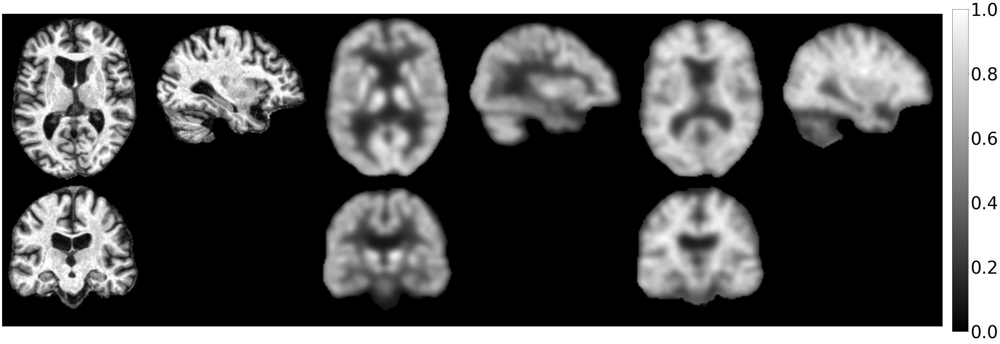

In [8]:
for batch in val_loader:
    image_mri =batch["mri"].to(device)
    seg_fdg = batch["fdg"].to(device) # this is the ground truth segmentation
    seg_av45 = batch["av45"].to(device)
    # fdg_index=batch["fdg_index"].to(device)
    # av45_index=batch["av45_index"].to(device)
    names = batch["name"]  # Extract subject information

   
    for idx, name in enumerate(names):
         print(f"Subject name: {name}")
    compare_3d([image_mri, seg_fdg,seg_av45])
    break  # Uncomment to compare only the first batch , label_1,label_2


In [9]:
from monai.networks.nets import ViT, ViTAutoEnc, SwinUNETR


roi = (160,192,160)
batch_size = 1
sw_batch_size = 2
infer_overlap = 0.5
max_epochs = 500
val_every = 10


model = SwinUNETR(
    img_size=(160,192,160),
    in_channels=1,
    out_channels=1,
    feature_size=48,
    drop_rate=0.0,
    attn_drop_rate=0.0,
    dropout_path_rate=0.0,
    use_checkpoint=False,
).to(device)
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-5)

/home/ssddata/liutuo/monai/utils/deprecate_utils.py:221: FutureWarning: monai.networks.nets.swin_unetr SwinUNETR.__init__:img_size: Argument `img_size` has been deprecated since version 1.3. It will be removed in version 1.5. The img_size argument is not required anymore and checks on the input size are run during forward().
  warn_deprecated(argname, msg, warning_category)


/tmp/ipykernel_1038742/2419426924.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch 0:   0%|                               | 0/1856 [00:00<?, ?it/s]/tmp/ipykernel_1038742/2419426924.py:62: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
Epoch 0: 100%|███████| 1856/1856 [27:24<00:00,  1.13it/s, loss=0.0231]


Epoch 1 Validation loss 0.007726083043962717
epoch: 1
learning rate: 1e-05
Saved all parameters!



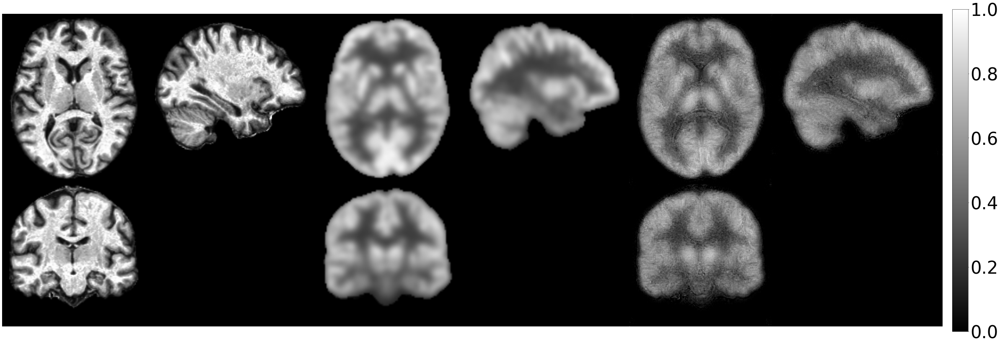

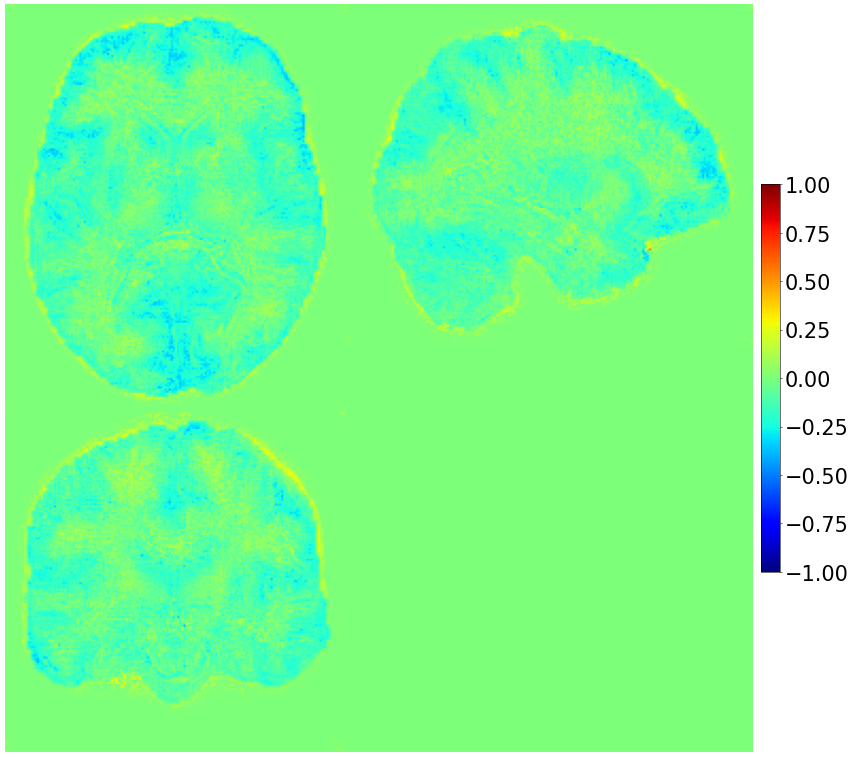

Average SSIM: tensor([[0.7292]], device='cuda:5')
Average PSNR: tensor([[21.1204]], device='cuda:5')


Epoch 1: 100%|███████| 1856/1856 [27:22<00:00,  1.13it/s, loss=0.0162]


Epoch 2 Validation loss 0.018706209491938353
epoch: 2
learning rate: 1e-05
Saved all parameters!



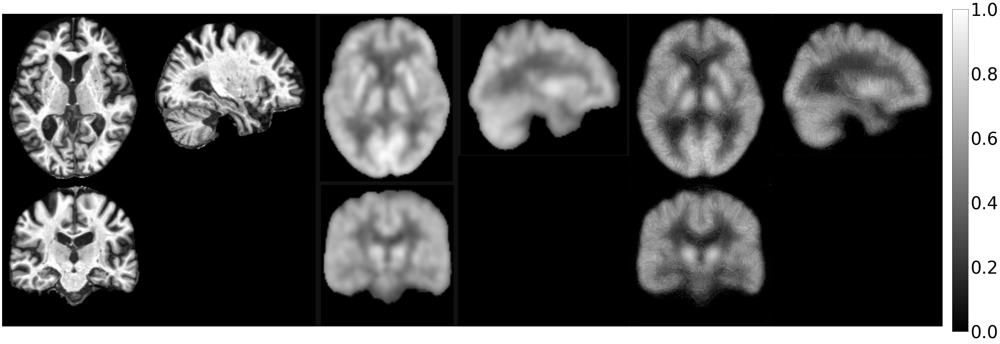

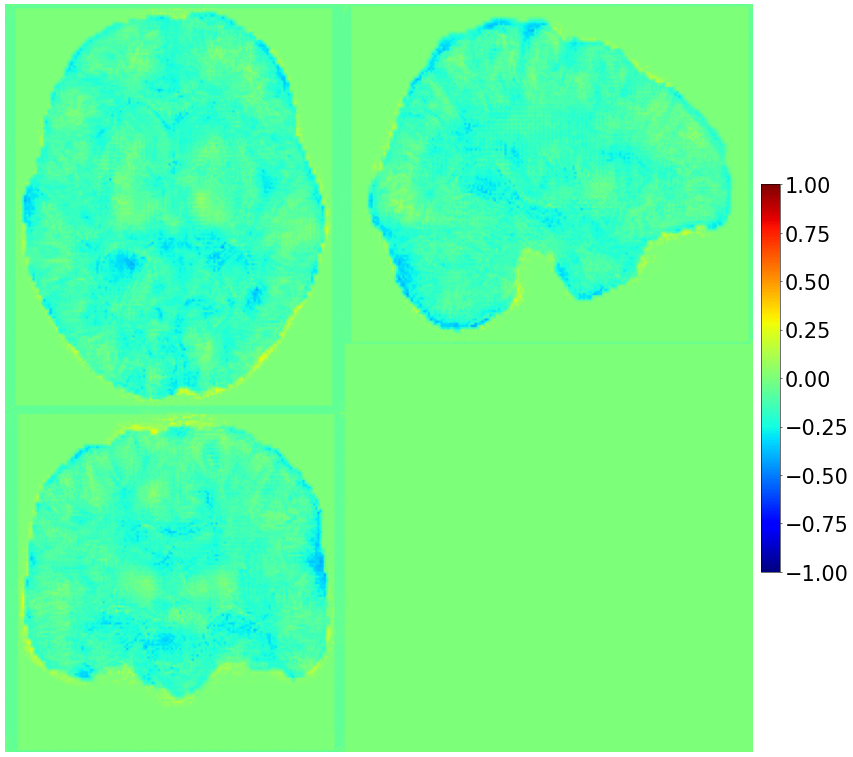

Average SSIM: tensor([[0.7086]], device='cuda:5')
Average PSNR: tensor([[19.5939]], device='cuda:5')


Epoch 2: 100%|███████| 1856/1856 [27:24<00:00,  1.13it/s, loss=0.0152]


Epoch 3 Validation loss 0.021344187203794718
epoch: 3
learning rate: 1e-05
Saved all parameters!



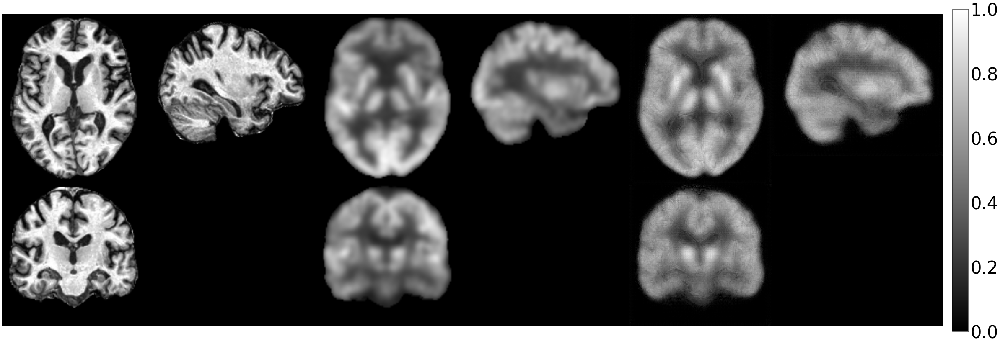

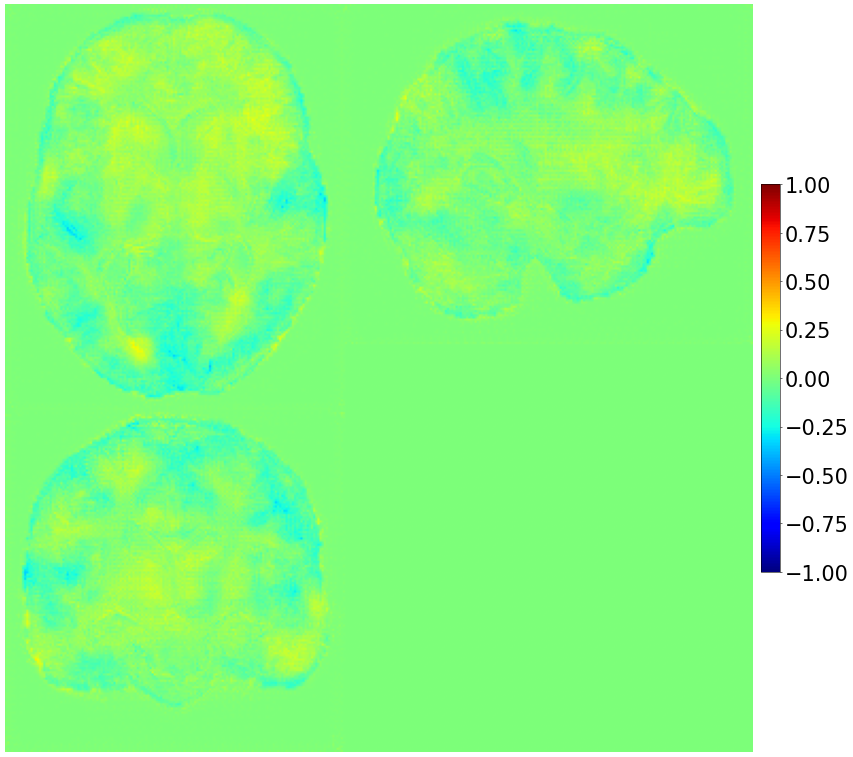

Average SSIM: tensor([[0.7658]], device='cuda:5')
Average PSNR: tensor([[25.7873]], device='cuda:5')


Epoch 3: 100%|███████| 1856/1856 [27:27<00:00,  1.13it/s, loss=0.0137]


Epoch 4 Validation loss 0.02303076023235917
epoch: 4
learning rate: 1e-05
Saved all parameters!



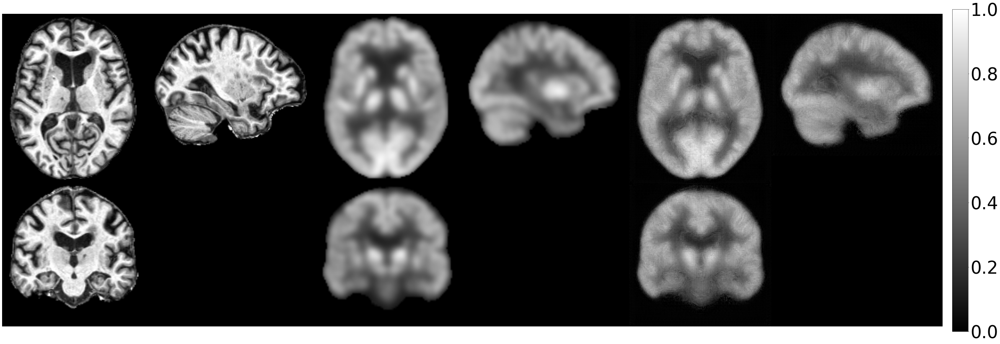

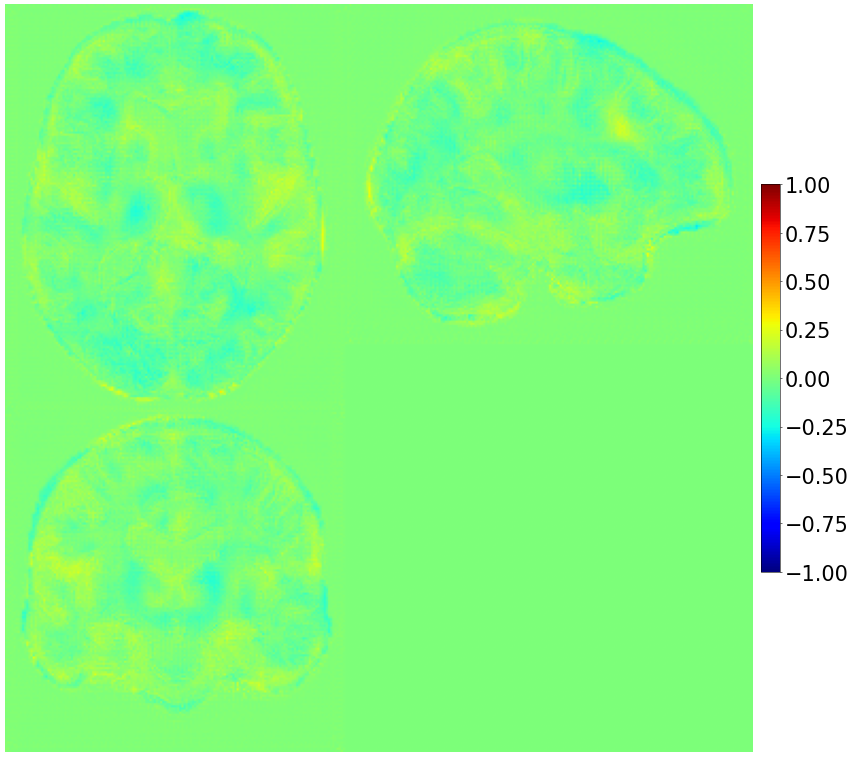

Average SSIM: tensor([[0.5990]], device='cuda:5')
Average PSNR: tensor([[27.7299]], device='cuda:5')


Epoch 4: 100%|███████| 1856/1856 [27:25<00:00,  1.13it/s, loss=0.0122]


Epoch 5 Validation loss 0.027139616198837757
epoch: 5
learning rate: 1e-05
Saved all parameters!



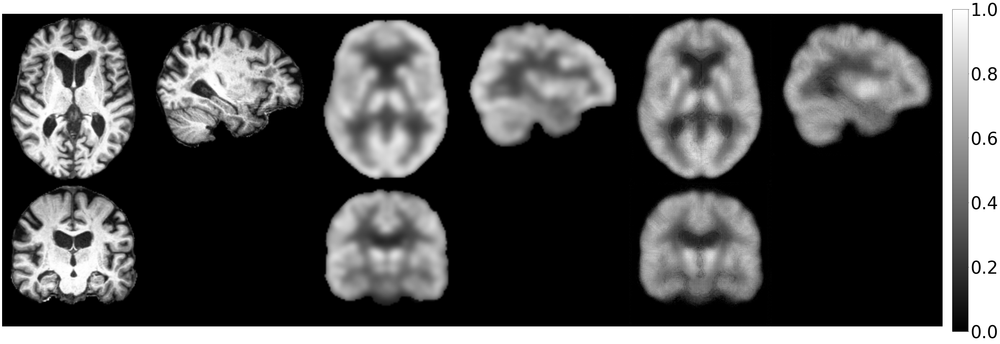

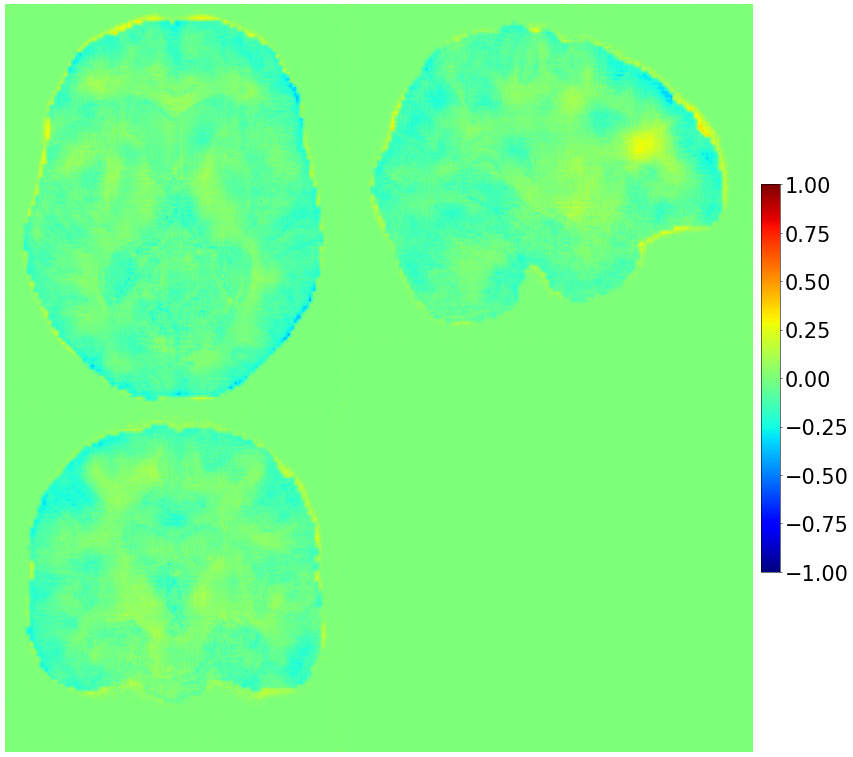

Average SSIM: tensor([[0.8413]], device='cuda:5')
Average PSNR: tensor([[23.8628]], device='cuda:5')


Epoch 5: 100%|████████| 1856/1856 [27:24<00:00,  1.13it/s, loss=0.011]


Epoch 6 Validation loss 0.11286570597440004
epoch: 6
learning rate: 1e-05
Saved all parameters!



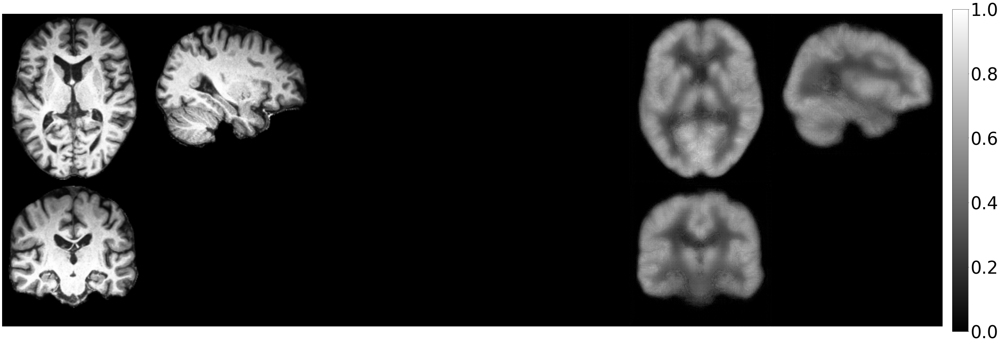

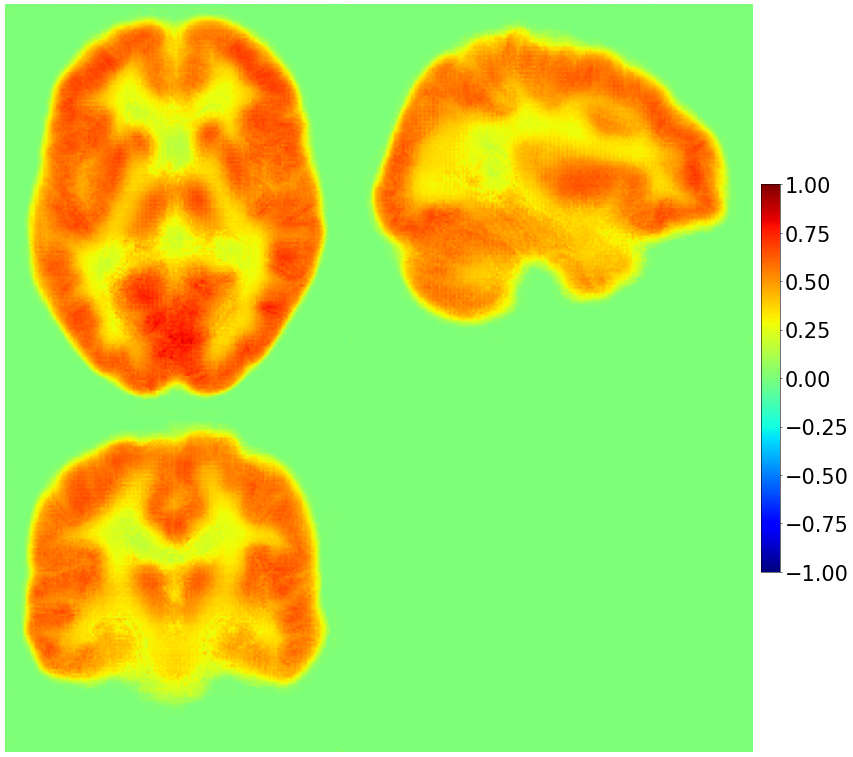

Average SSIM: tensor([[0.4508]], device='cuda:5')
Average PSNR: tensor([[10.6689]], device='cuda:5')


Epoch 6: 100%|██████| 1856/1856 [27:23<00:00,  1.13it/s, loss=0.00902]


Epoch 7 Validation loss 0.11564350710250437
epoch: 7
learning rate: 1e-05
Saved all parameters!



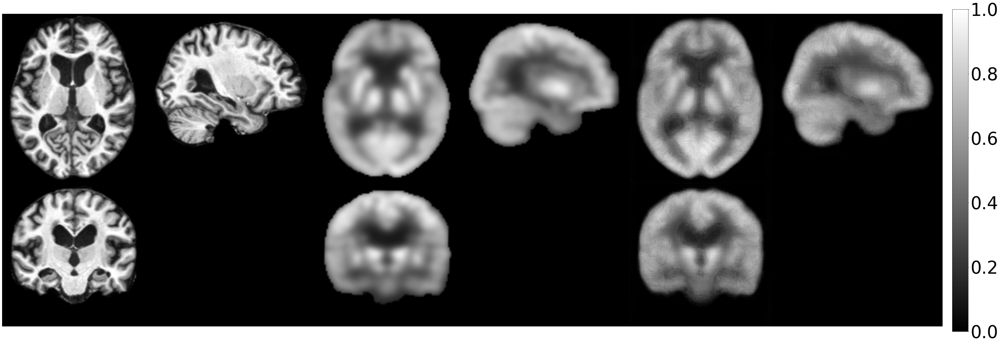

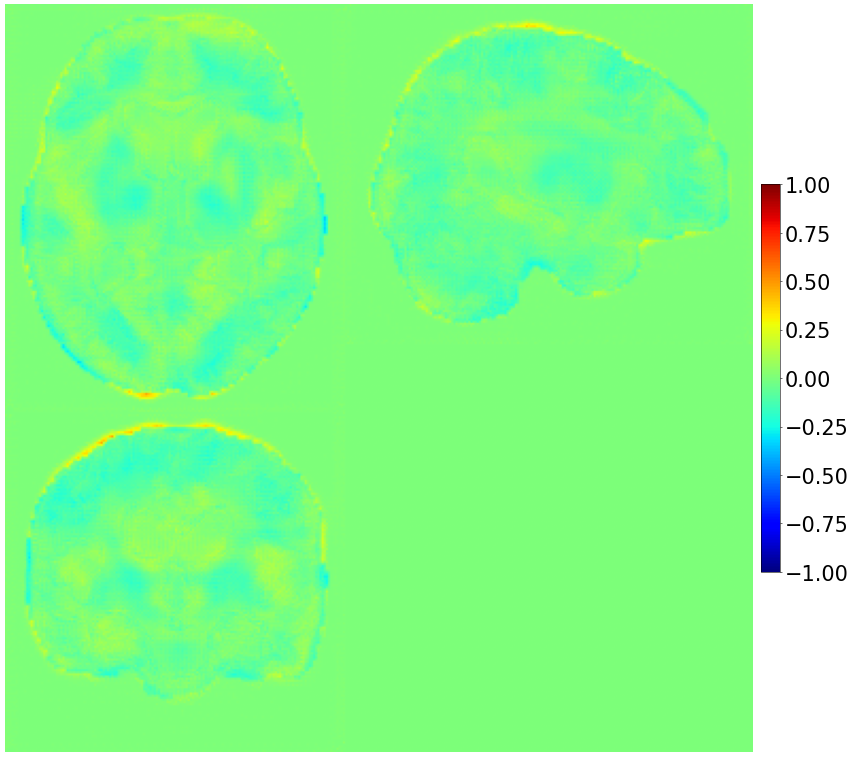

Average SSIM: tensor([[0.8368]], device='cuda:5')
Average PSNR: tensor([[25.5630]], device='cuda:5')


Epoch 7: 100%|██████| 1856/1856 [27:24<00:00,  1.13it/s, loss=0.00662]


Epoch 8 Validation loss 0.11619846837129444
epoch: 8
learning rate: 1e-05
Saved all parameters!



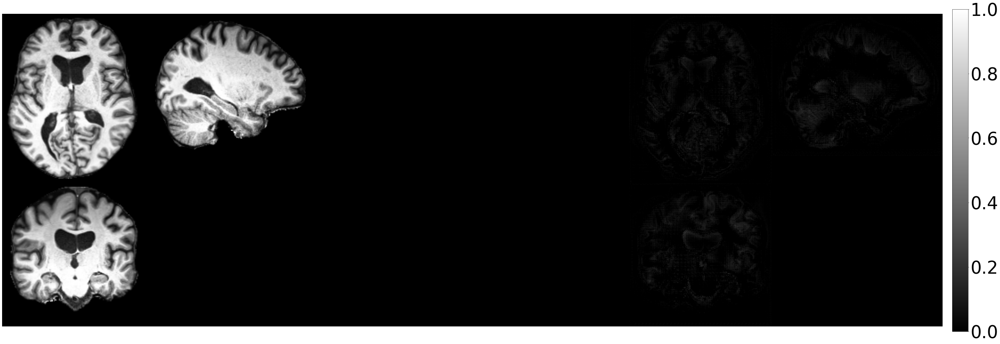

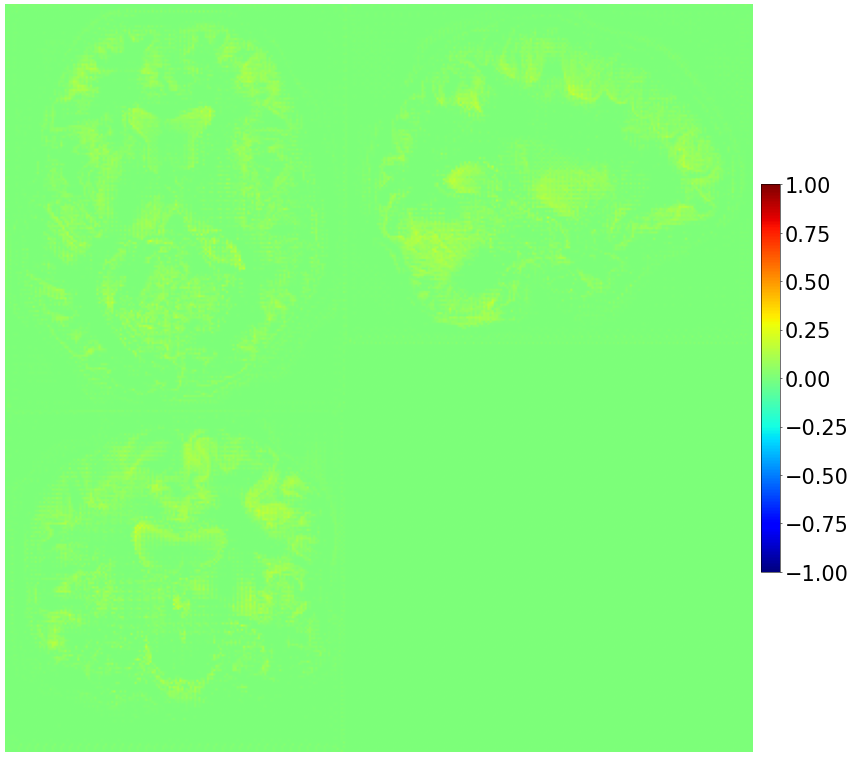

Average SSIM: tensor([[0.6117]], device='cuda:5')
Average PSNR: tensor([[32.5574]], device='cuda:5')


Epoch 8: 100%|██████| 1856/1856 [27:22<00:00,  1.13it/s, loss=0.00508]


Epoch 9 Validation loss 0.11904455360490829
epoch: 9
learning rate: 1e-05
Saved all parameters!



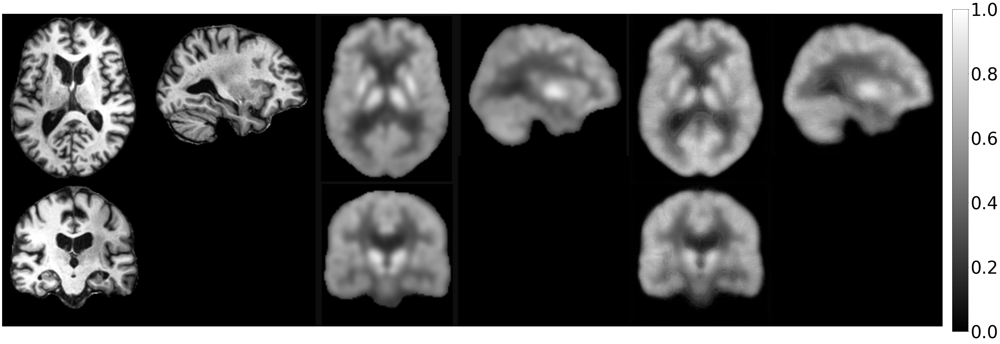

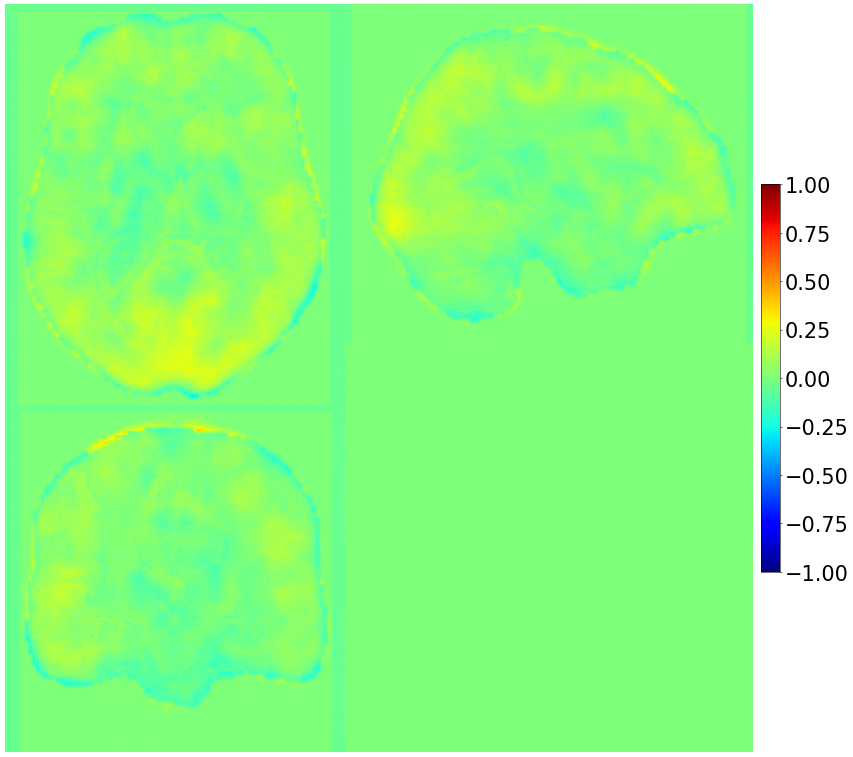

Average SSIM: tensor([[0.7979]], device='cuda:5')
Average PSNR: tensor([[25.4575]], device='cuda:5')


Epoch 9: 100%|██████| 1856/1856 [27:25<00:00,  1.13it/s, loss=0.00399]


Epoch 10 Validation loss 0.12156013364437968
epoch: 10
learning rate: 1e-05
Saved all parameters!



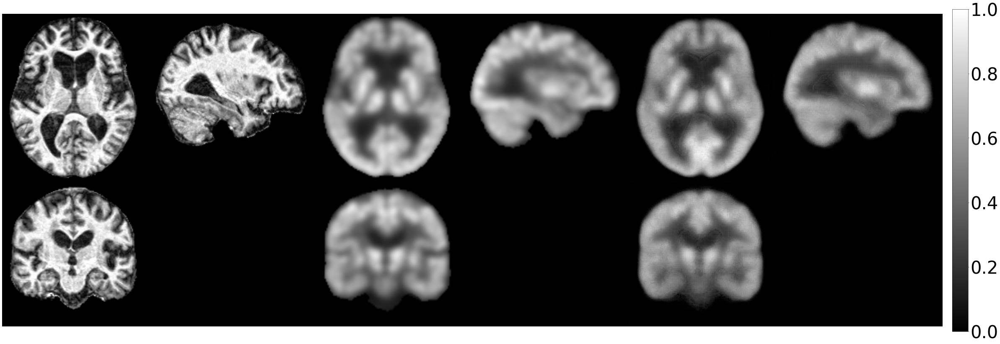

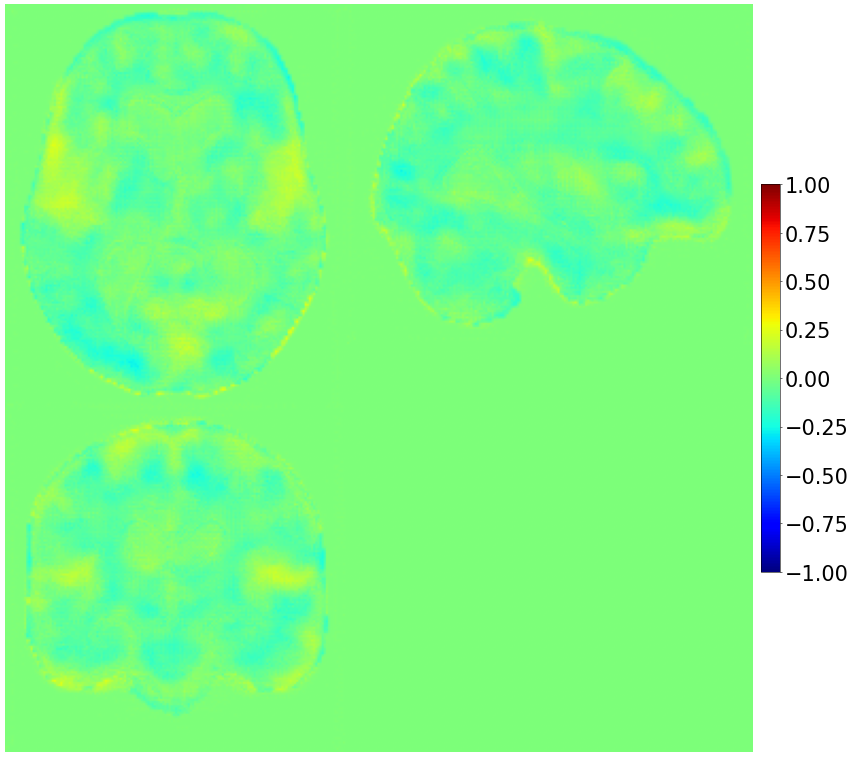

Average SSIM: tensor([[0.8708]], device='cuda:5')
Average PSNR: tensor([[25.9936]], device='cuda:5')


Epoch 10: 100%|███████| 1856/1856 [27:26<00:00,  1.13it/s, loss=0.004]


Epoch 11 Validation loss 0.12437588267493993
epoch: 11
learning rate: 1e-05
Saved all parameters!



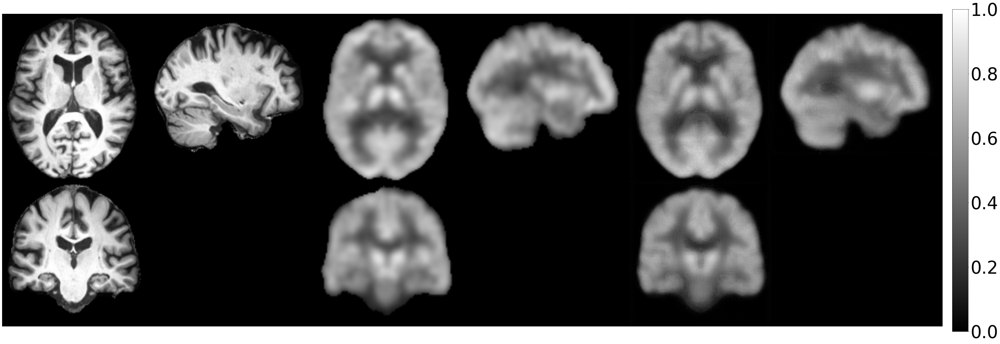

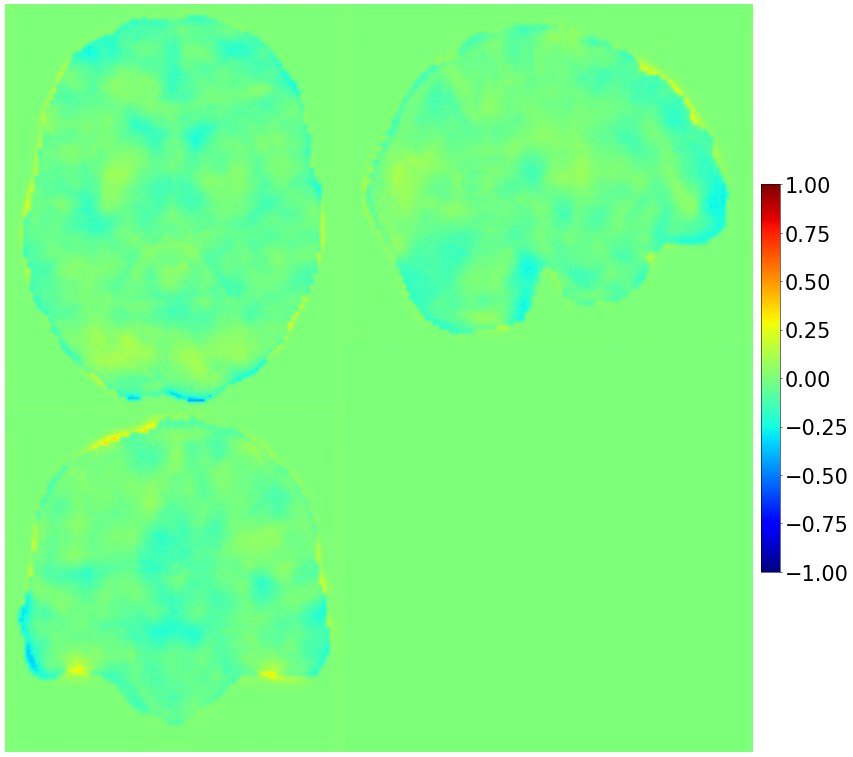

Average SSIM: tensor([[0.8198]], device='cuda:5')
Average PSNR: tensor([[25.5041]], device='cuda:5')


Epoch 11: 100%|██████| 1856/1856 [27:24<00:00,  1.13it/s, loss=0.0037]


Epoch 12 Validation loss 0.124907185905613
epoch: 12
learning rate: 1e-05
Saved all parameters!



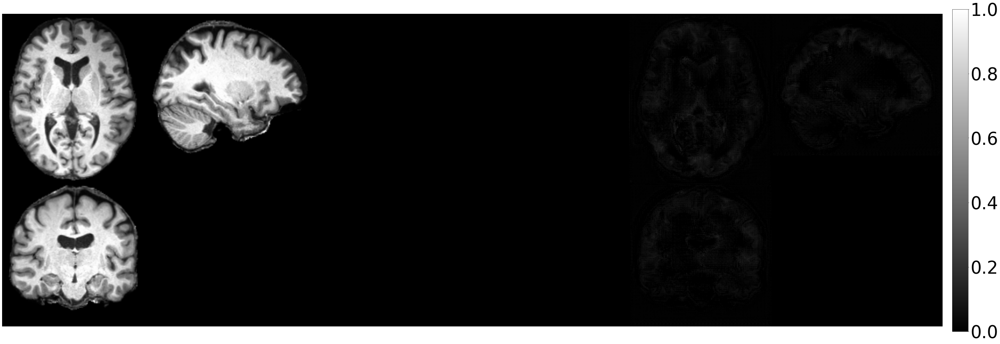

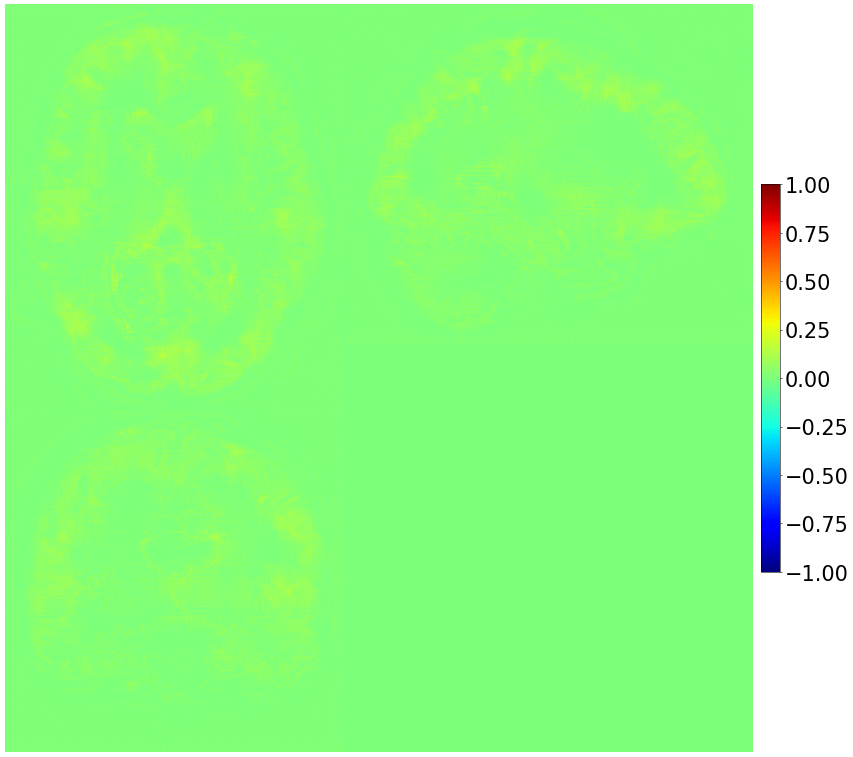

Average SSIM: tensor([[0.3831]], device='cuda:5')
Average PSNR: tensor([[32.7466]], device='cuda:5')


Epoch 12: 100%|█████| 1856/1856 [27:24<00:00,  1.13it/s, loss=0.00263]


Epoch 13 Validation loss 0.12649732560385019
epoch: 13
learning rate: 1e-05
Saved all parameters!



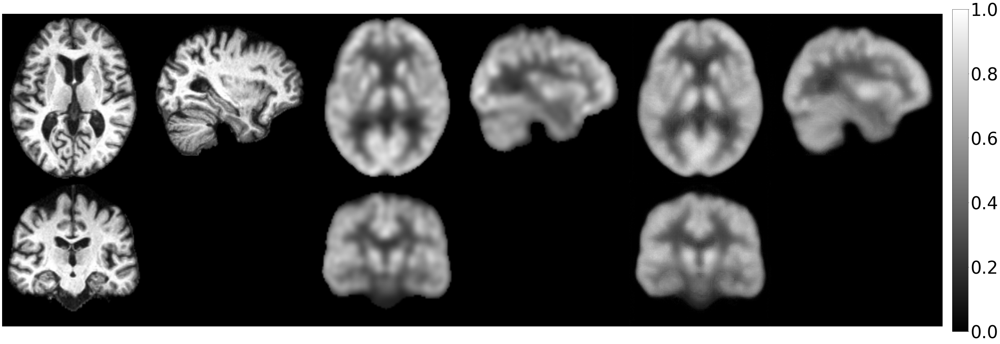

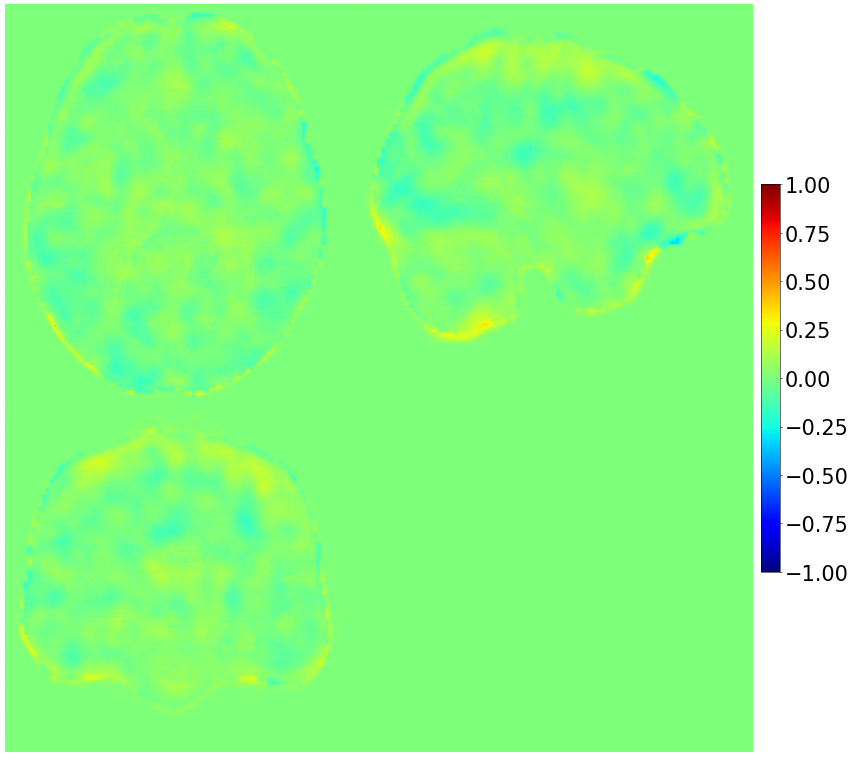

Average SSIM: tensor([[0.8788]], device='cuda:5')
Average PSNR: tensor([[27.9856]], device='cuda:5')


In [8]:
from torch.cuda.amp import GradScaler, autocast
import os

import matplotlib.pyplot as plt
import torch
import json
import torch.nn as nn

import torch.nn.functional as F
from monai import transforms
from monai.config import print_config
from monai import data
from monai.utils import first, set_determinism
from torch.cuda.amp import GradScaler, autocast
from monai.data import CacheDataset, DataLoader
from monai.networks.nets import ViT, ViTAutoEnc, SwinUNETR
from tqdm import tqdm

from generative.inferers import DiffusionInferer
from generative.networks.nets import AutoencoderKL, DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler, DDIMScheduler
import random
import time
import matplotlib.pyplot as plt
import numpy as np

from generative.metrics import SSIMMetric
from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
checkpoint_dir = '/home/ssddata/liutuo/checkpoint/swinunter_fdg'
n_epochs = 13
val_interval = 1 #10
epoch_loss_list = []
val_epoch_loss_list = []
val_epoch_loss = 0
start_epoch = 0
from generative.metrics import SSIMMetric
from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=7)
psnr_metric=PSNRMetric(1.0)
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值

scaler = GradScaler()


for epoch in range(start_epoch, n_epochs):
    epoch
    model.train()
    epoch_loss = 0

    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")

    for step, data in progress_bar:
        images = data["mri"].to(device)  
        targets = data["fdg"].to(device)  

 

        optimizer.zero_grad(set_to_none=True)
    
        with autocast(enabled=True):

            t1ce_pre = model(images)
            loss = F.mse_loss(targets.float(), t1ce_pre.float())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()

        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})

    epoch_loss_list.append(epoch_loss / (step + 1))
    
    if (epoch) % val_interval == 0 or (epoch == 0):
        model.eval()
        ssim_values = []
        psnr_values = []

        with torch.no_grad():
            for step, batch in enumerate(val_loader):
                images = data["mri"].to(device)  # 确保将张量加载到 GPU
                targets = data["fdg"].to(device)  # 确保目标也在 GPU

                t1ce_pre= model(images)
                t1ce_pre= torch.clamp(t1ce_pre, min=clip_sample_min, max=clip_sample_max)
                val_loss =F.mse_loss(targets.float(), t1ce_pre.float())
                val_epoch_loss += val_loss.item()
                torch.cuda.empty_cache()
            print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
            val_epoch_loss_list.append(val_epoch_loss / (step + 1))
            # Saving model parameters
            print('epoch:', epoch + 1)
            print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
            checkpoint = {
                'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'epoch': epoch
            }
            torch.save(checkpoint, f'{checkpoint_dir}/swinunter_{epoch + 1}.pth')
            print('Saved all parameters!\n')
        

            ssim_value = ssim_metric(targets, t1ce_pre)
            psnr_value = psnr_metric(targets, t1ce_pre)
            # print(f"SSIM: {ssim_value.mean().item()}")
            # print(f"PSNR: {psnr_value.mean().item()}") 
            # 将当前批次的 SSIM 和 PSNR 值添加到列表中
            ssim_values.append(ssim_value)
            psnr_values.append(psnr_value)
            current_img =  t1ce_pre.to('cpu')
            labels = targets.to('cpu')
            compare_3d([images,labels, current_img])
            compare_3d_jet([current_img - labels])



        # 计算平均 SSIM 和 PSNR 值
        average_ssim = sum(ssim_values) / len(ssim_values)
        average_psnr = sum(psnr_values) / len(psnr_values)

        print(f"Average SSIM: {average_ssim}")
        print(f"Average PSNR: {average_psnr}")

  0%|                                                                                                                                                                                                                                                   | 0/1 [00:00<?, ?it/s]/tmp/ipykernel_3425651/877954644.py:59: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


Processed: /home/ssddata/liutuo/liutuo_data/test1/temp_generated_image_0.nii.gz
Saved flipped image to: /home/ssddata/liutuo/liutuo_data/test1/flipped_xyz_temp_generated_image_0.nii.gz


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.66s/it]

All generated and flipped images have been saved to /home/ssddata/liutuo/liutuo_data/test1


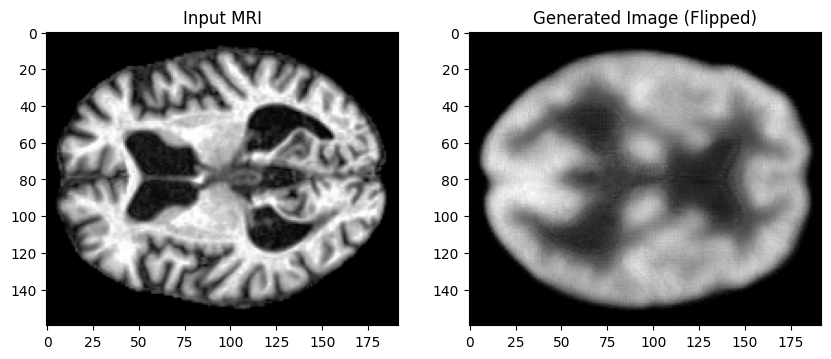

In [14]:
import os
import torch
import numpy as np
from monai.networks.nets import SwinUNETR
from monai.data import DataLoader, Dataset
from monai.transforms import Compose, LoadImage, EnsureChannelFirst, ScaleIntensity, ToTensor
from tqdm import tqdm
import matplotlib.pyplot as plt
import nibabel as nib

# 定义路径和参数
checkpoint_path = "/home/ssddata/liutuo/checkpoint/swinunter_fdg/swinunter_10.pth"
output_dir = "/home/ssddata/liutuo/liutuo_data/test1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 创建输出目录
os.makedirs(output_dir, exist_ok=True)

# 加载模型
model = SwinUNETR(
    img_size=(96, 96, 96),  # 根据你的数据调整大小
    in_channels=1,          # 输入通道数
    out_channels=1,         # 输出通道数
    feature_size=48,        # 特征大小
).to(device)

# 加载检查点
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model'])
model.eval()

# 定义翻转函数
def flip_nifti_along_xyz(file_path, output_dir):
    """
    沿 x、y、z 轴翻转 NIfTI 文件并保存。
    """
    # 加载 NIfTI 文件
    img = nib.load(file_path)
    data = img.get_fdata()  # 获取图像数据（NumPy 数组）
    affine = img.affine      # 获取仿射矩阵

    # 同时沿 x 轴、y 轴和 z 轴翻转
    flipped_xyz = np.flip(data, axis=(0, 1, 2))  # 沿 (x, y, z) 轴同时翻转
    flipped_img_xyz = nib.Nifti1Image(flipped_xyz, affine)

    # 构造输出文件名
    output_path_xyz = os.path.join(output_dir, f"flipped_xyz_{os.path.basename(file_path)}")
    nib.save(flipped_img_xyz, output_path_xyz)

    print(f"Processed: {file_path}")
    print(f"Saved flipped image to: {output_path_xyz}")

# 推理过程
with torch.no_grad():
    for i, data in enumerate(tqdm(train_loader)):
        images = data["mri"].to(device)

        # 模型推理
        with torch.cuda.amp.autocast(enabled=True):
            outputs = model(images)

        # 将输出限制在合理范围内（如果需要）
        outputs = torch.clamp(outputs, min=0, max=1.0)

        # 将 PyTorch 张量转换为 NumPy 数组
        output_image = outputs.squeeze().cpu().numpy().astype(np.float32)  # 转换为 float32

        # 保存生成的图像为临时 NIfTI 文件
        temp_output_path = os.path.join(output_dir, f"temp_generated_image_{i}.nii.gz")
        temp_output_nifti = nib.Nifti1Image(output_image, affine=np.eye(4))  # 创建 NIfTI 图像
        nib.save(temp_output_nifti, temp_output_path)  # 保存为 .nii.gz

        # 对生成的图像进行翻转处理
        flip_nifti_along_xyz(temp_output_path, output_dir)

        # 删除临时文件
        os.remove(temp_output_path)

        # 可视化生成的图像（可选）
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.title("Input MRI")
        plt.imshow(images[0, 0, :, :, images.shape[-1] // 2].cpu().numpy(), cmap="gray")  # 显示中间切片

        plt.subplot(1, 2, 2)
        plt.title("Generated Image (Flipped)")
        flipped_data = nib.load(os.path.join(output_dir, f"flipped_xyz_temp_generated_image_{i}.nii.gz")).get_fdata()
        plt.imshow(flipped_data[:, :, flipped_data.shape[-1] // 2], cmap="gray")  # 显示中间切片

        plt.savefig(os.path.join(output_dir, f"visualization_flipped_{i}.png"))


print(f"All generated and flipped images have been saved to {output_dir}")

Image saved to /home/ssddata/liutuo/radar_chartfdg.png


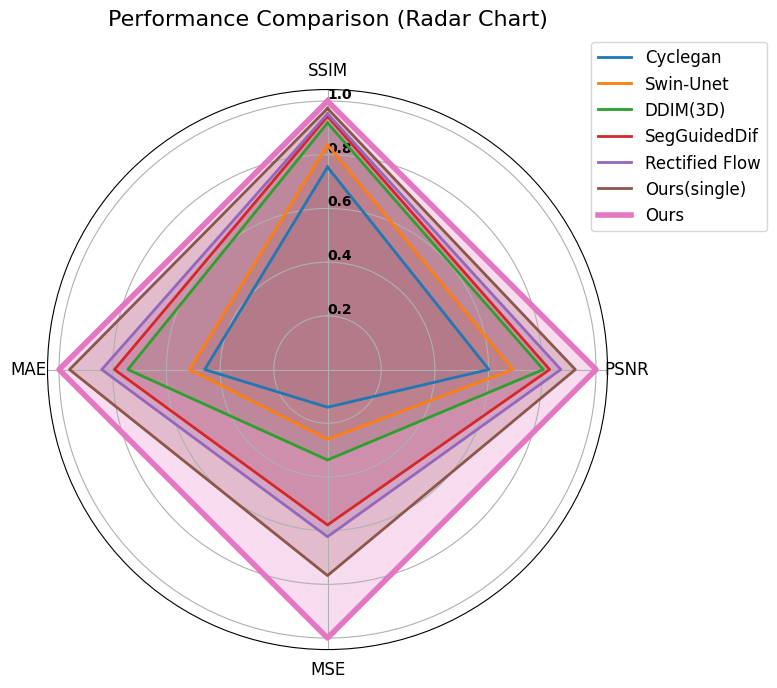

In [37]:

import numpy as np
import matplotlib.pyplot as plt
from math import pi
# 数据定义
methods = ['Cyclegan', 'Swin-Unet', 'DDIM(3D)', 'SegGuidedDif', 'Rectified Flow', 'Ours(single)', 'Ours']
metrics = ['SSIM (%) ↑', 'PSNR ↑', 'MSE (%) ↓', 'MAE (%) ↓']  # 标注方向性
data = [
    [67.82, 17.26, 2.35, 6.47],  # Cyclegan
    [75.29, 19.82, 1.27, 5.76],  # Swin-Unet
    [82.62, 23.09, 0.98, 3.98],  # DDIM(3D)
    [84.85, 23.76, 0.57, 3.73],  # SegGuidedDif
    [85.69, 24.96, 0.53, 3.52],  # Rectified Flow
    [87.48, 26.51, 0.43, 3.08],  # Ours(single)
    [89.94, 28.72, 0.33, 2.96]   # Ours
]

# 数据标准化处理（对于↑指标越大越好，对于↓指标越小越好）
def normalize_data(data):
    normalized_data = []
    for row in data:
        norm_row = []
        for i, value in enumerate(row):
            if "↑" in metrics[i]:  # 越大越好
                norm_row.append(value / max([r[i] for r in data]))
            elif "↓" in metrics[i]:  # 越小越好
                norm_row.append(min([r[i] for r in data]) / value)
        normalized_data.append(norm_row)
    return normalized_data

normalized_data = normalize_data(data)

# 创建雷达图
def plot_radar_chart(methods, metrics, data, save_path=None):
    num_vars = len(metrics)
    angles = np.linspace(0, 2 * pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]  # 闭合图形

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # 绘制每个方法的线
    colors = plt.cm.tab10.colors  # 使用 tab10 颜色映射
    for i, method in enumerate(methods):
        values = data[i]
        values += values[:1]  # 闭合图形
        linewidth = 2 if method != 'Ours' else 4  # 突出 'Ours'
        ax.plot(angles, values, color=colors[i], label=method, linewidth=linewidth)
        ax.fill(angles, values, color=colors[i], alpha=0.25)

    # 设置标签
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), [m.split(" ")[0] for m in metrics], fontsize=12)

    # 增加网格线
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8, 1.0], angle=0, weight='black', fontsize=10)

    # 添加图例和标题
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=12)
    plt.title("Performance Comparison (Radar Chart)", size=16, y=1.1)

    # 调整布局
    plt.tight_layout()

    # 如果提供了保存路径，则保存图像
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)  # 确保目录存在
        plt.savefig(save_path, dpi=300, bbox_inches='tight')  # 保存图像，设置高分辨率
        print(f"Image saved to {save_path}")

    plt.show()

# 指定保存路径
save_path = "/home/ssddata/liutuo/radar_chartfdg.png"

# 调用函数绘制蛛网图并保存
plot_radar_chart(methods, metrics, normalized_data, save_path)

Image saved to /home/ssddata/liutuo/radar_chartav45.png


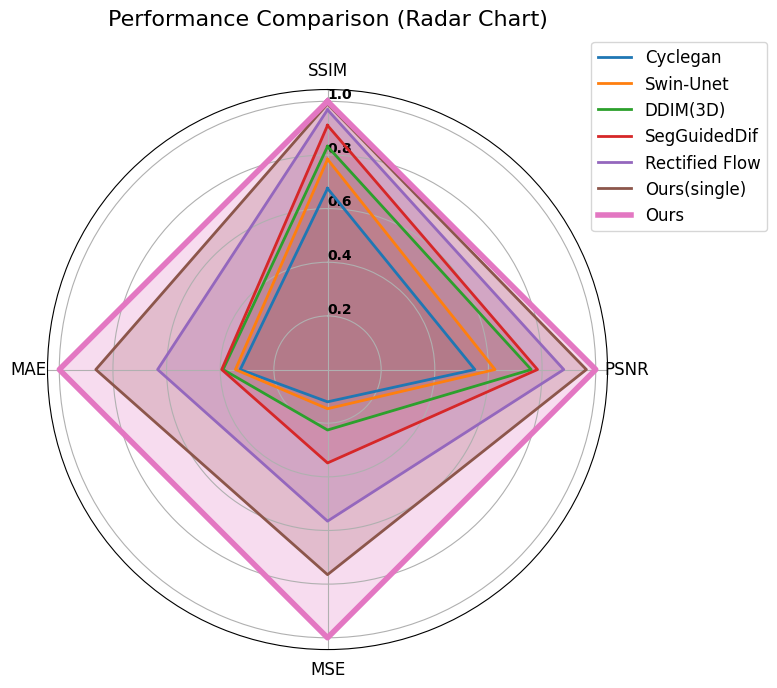

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

# 数据定义
methods = ['Cyclegan', 'Swin-Unet', 'DDIM(3D)', 'SegGuidedDif', 'Rectified Flow', 'Ours(single)', 'Ours']
metrics = ['SSIM (%) ↑', 'PSNR ↑', 'MSE (%) ↓', 'MAE (%) ↓']  # 标注方向性
data = [
    [59.56, 15.43, 3.24, 8.39],  # Cyclegan
    [69.16, 17.54, 2.67, 7.95],  # Swin-Unet
    [73.37, 21.33, 1.73, 7.01],  # DDIM(3D)
    [80.29, 21.99, 1.12, 6.92],  # SegGuidedDif
    [85.43, 24.74, 0.69, 4.31],  # Rectified Flow
    [87.37, 27.11, 0.51, 3.16],  # Ours(single)
    [88.21, 28.09, 0.39, 2.73]   # Ours
]

# 数据标准化处理（对于↑指标越大越好，对于↓指标越小越好）
# 数据标准化处理（对于↑指标越大越好，对于↓指标越小越好）
def normalize_data(data):
    normalized_data = []
    for row in data:
        norm_row = []
        for i, value in enumerate(row):
            if "↑" in metrics[i]:  # 越大越好
                norm_row.append(value / max([r[i] for r in data]))
            elif "↓" in metrics[i]:  # 越小越好
                norm_row.append(min([r[i] for r in data]) / value)
        normalized_data.append(norm_row)
    return normalized_data

normalized_data = normalize_data(data)

# 创建雷达图
def plot_radar_chart(methods, metrics, data, save_path=None):
    num_vars = len(metrics)
    angles = np.linspace(0, 2 * pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]  # 闭合图形

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # 绘制每个方法的线
    colors = plt.cm.tab10.colors  # 使用 tab10 颜色映射
    for i, method in enumerate(methods):
        values = data[i]
        values += values[:1]  # 闭合图形
        linewidth = 2 if method != 'Ours' else 4  # 突出 'Ours'
        ax.plot(angles, values, color=colors[i], label=method, linewidth=linewidth)
        ax.fill(angles, values, color=colors[i], alpha=0.25)

    # 设置标签
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), [m.split(" ")[0] for m in metrics], fontsize=12)

    # 增加网格线
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8, 1.0], angle=0, weight='black', fontsize=10)

    # 添加图例和标题
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=12)
    plt.title("Performance Comparison (Radar Chart)", size=16, y=1.1)

    # 调整布局
    plt.tight_layout()

    # 如果提供了保存路径，则保存图像
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)  # 确保目录存在
        plt.savefig(save_path, dpi=300, bbox_inches='tight')  # 保存图像，设置高分辨率
        print(f"Image saved to {save_path}")

    plt.show()

# 指定保存路径
save_path = "/home/ssddata/liutuo/radar_chartav45.png"

# 调用函数绘制蛛网图并保存
plot_radar_chart(methods, metrics, normalized_data, save_path)

Image saved to /home/ssddata/liutuo/radar_chartfanhua.png


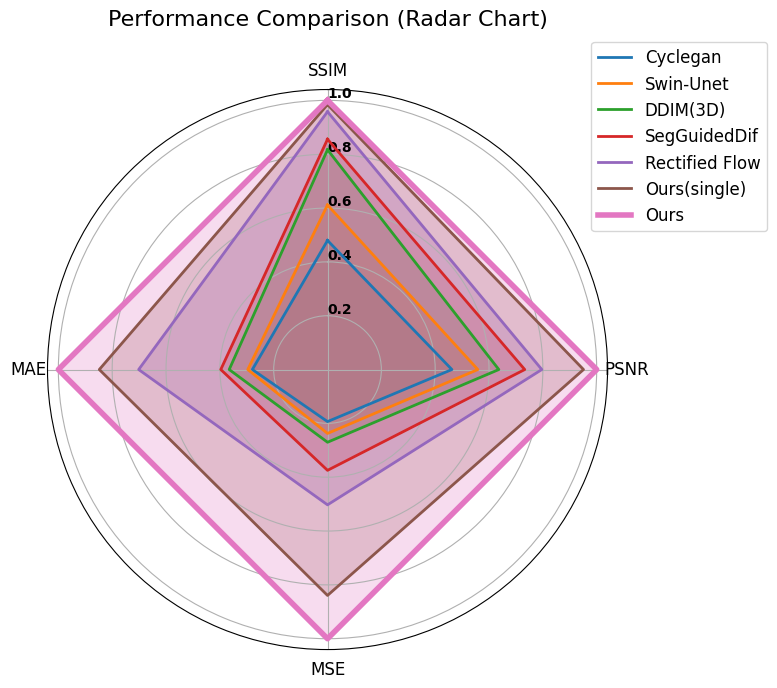

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import os

# 数据定义
methods = ['Cyclegan', 'Swin-Unet', 'DDIM(3D)', 'SegGuidedDif', 'Rectified Flow', 'Ours(single)', 'Ours']
metrics = ['SSIM (%) ↑', 'PSNR ↑', 'MSE (%) ↓', 'MAE (%) ↓']  # 标注方向性
data = [
    [40.27, 12.38, 4.86, 10.78],  # Cyclegan
    [51.34, 14.96, 3.96, 10.16],  # Swin-Unet
    [68.59, 17.05, 3.48, 8.24],   # DDIM(3D)
    [71.85, 19.63, 2.51, 7.59],   # SegGuidedDif
    [80.44, 21.33, 1.87, 4.29],   # Rectified Flow
    [82.66, 25.48, 1.12, 3.55],   # Ours(single)
    [83.97, 26.79, 0.94, 3.01]    # Ours
]

# 数据标准化处理（对于↑指标越大越好，对于↓指标越小越好）
def normalize_data(data):
    normalized_data = []
    for row in data:
        norm_row = []
        for i, value in enumerate(row):
            if "↑" in metrics[i]:  # 越大越好
                norm_row.append(value / max([r[i] for r in data]))
            elif "↓" in metrics[i]:  # 越小越好
                norm_row.append(min([r[i] for r in data]) / value)
        normalized_data.append(norm_row)
    return normalized_data

normalized_data = normalize_data(data)

# 创建雷达图
def plot_radar_chart(methods, metrics, data, save_path=None):
    num_vars = len(metrics)
    angles = np.linspace(0, 2 * pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]  # 闭合图形

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # 绘制每个方法的线
    colors = plt.cm.tab10.colors  # 使用 tab10 颜色映射
    for i, method in enumerate(methods):
        values = data[i]
        values += values[:1]  # 闭合图形
        linewidth = 2 if method != 'Ours' else 4  # 突出 'Ours'
        ax.plot(angles, values, color=colors[i], label=method, linewidth=linewidth)
        ax.fill(angles, values, color=colors[i], alpha=0.25)

    # 设置标签
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), [m.split(" ")[0] for m in metrics], fontsize=12)

    # 增加网格线
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8, 1.0], angle=0, weight='black', fontsize=10)

    # 添加图例和标题
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=12)
    plt.title("Performance Comparison (Radar Chart)", size=16, y=1.1)

    # 调整布局
    plt.tight_layout()

    # 如果提供了保存路径，则保存图像
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)  # 确保目录存在
        plt.savefig(save_path, dpi=300, bbox_inches='tight')  # 保存图像，设置高分辨率
        print(f"Image saved to {save_path}")

    plt.show()

# 指定保存路径
save_path = "/home/ssddata/liutuo/radar_chartfanhua.png"

# 调用函数绘制蛛网图并保存
plot_radar_chart(methods, metrics, normalized_data, save_path)